# Day 1: get to know MC_RTT

**The problem in one sentence.** A monkey moves its finger to random targets while ~130 neurons in its motor cortex are recorded. We want a function that reads the recent spikes and outputs the current finger velocity, using only the past (so it could run live in a BCI).

**Vocabulary**
- **Spike**: a neuron's all-or-nothing electrical pulse. We only keep *when* each spike happened.
- **Unit**: one recorded neuron (or a small group the spike sorter could not separate).
- **Bin**: a short time window (we will use 20 ms). Spikes are counted per bin, so the input is a matrix `counts[time, unit]` of small integers.
- **Tuning**: a motor-cortex neuron fires more when the hand moves in its *preferred direction*. That is why a mostly linear readout of many neurons recovers velocity.
- **Lag**: neural activity *precedes* movement by ~100 ms (the brain sends the command, then the arm moves).
- **Causal**: the decoder at time t may only use spikes up to t. No peeking at the future.

**Today's goals:** load the data, confirm the unit count and field names, look at a raster and the velocity, see tuning with your own eyes, and get a first feel for the lag.

## 0. Download the data (once)

MC_RTT is DANDI dataset **000129**. From the repo root, in a terminal:

```
mkdir data
uvx dandi download DANDI:000129/draft -o data
```

This should create `data/000129/sub-Indy/` with a `*train*.nwb` and a `*test*.nwb` file. We only use the **train** file: it is the one that contains the behaviour (the test file's behaviour is hidden for the benchmark). Our own train/val/test split will be cut from it, in time order.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nlb_tools.nwb_interface import NWBDataset

DATA_DIR = Path("../../data/000129/sub-Indy")
print(sorted(p.name for p in DATA_DIR.glob("*.nwb")))

['sub-Indy_desc-test_ecephys.nwb', 'sub-Indy_desc-train_behavior+ecephys.nwb']


## 1. Load and inspect

`split_heldout=False` keeps all units together (the benchmark normally hides some of them; we don't need that). The data arrive at 1 ms resolution, as one big DataFrame whose columns are grouped by signal (`spikes`, `finger_vel`, ...).

In [14]:
dataset = NWBDataset(str(DATA_DIR), "*train", split_heldout=False)
# Spikes are stored as float16, which cannot sum ~650k rows correctly (means come out 0).
# Cast to float32 once, here; resample() keeps this dtype.
dataset.data = dataset.data.astype({c: np.float32 for c in dataset.data.columns if c[0] == "spikes"})
df = dataset.data

print("bin width (ms):", dataset.bin_width)
print("duration (min):", round(df.index[-1].total_seconds() / 60, 1))
print("signals:", list(df.columns.get_level_values(0).unique()))
print("n units:", df["spikes"].shape[1])
for sig in ["finger_pos", "finger_vel", "cursor_pos", "target_pos"]:
    if sig in df:
        print(f"{sig:12s} columns: {list(df[sig].columns)}")
df.head()

c:\Users\adrie\dev\mc_rtt_decoder\.venv\lib\site-packages\hdmf\spec\namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.4.0, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


bin width (ms): 1
duration (min): 10.8
signals: ['cursor_pos', 'finger_pos', 'finger_vel', 'spikes', 'target_pos']
n units: 130
finger_pos   columns: ['x', 'y', 'z']
finger_vel   columns: ['x', 'y']
cursor_pos   columns: ['x', 'y']
target_pos   columns: ['x', 'y']


signal_type            cursor_pos            finger_pos                        \
channel                         x          y          x          y          z   
clock_time                                                                      
0 days 00:00:00         -4.368126  56.778511  -4.357695  56.758063  94.737781   
0 days 00:00:00.001000  -4.367445  56.776709  -4.356471  56.755696  94.736662   
0 days 00:00:00.002000  -4.366716  56.774849  -4.355222  56.753297  94.735519   
0 days 00:00:00.003000  -4.365940  56.772930  -4.353950  56.750865  94.734355   
0 days 00:00:00.004000  -4.365118  56.770954  -4.352654  56.748402  94.733168   

signal_type            finger_vel           spikes            ...            \
channel                         x         y    201  203  204  ... 9201 9203   
clock_time                                                    ...             
0 days 00:00:00          1.211079 -2.349968    0.0  0.0  0.0  ...  0.0  0.0   
0 days 00:00:00.001000   1.236134 -2.383193    0.0  0.0  0.0  ...  0.0  0.0   
0 days 00:00:00.002000   1.260579 -2.415633    0.0  0.0  0.0  ...  0.0  0.0   
0 days 00:00:00.003000   1.284410 -2.447283    0.0  0.0  0.0  ...  0.0  0.0   
0 days 00:00:00.004000   1.307626 -2.478143    0.0  0.0  0.0  ...  0.0  0.0   

signal_type                                          target_pos        
channel                9301 9403 9501 9502 9601 9602          x     y  
clock_time                                                             
0 days 00:00:00         0.0  0.0  0.0  0.0  0.0  0.0       -7.5  52.5  
0 days 00:00:00.001000  0.0  0.0  0.0  0.0  0.0  0.0       -7.5  52.5  
0 days 00:00:00.002000  0.0  0.0  0.0  0.0  0.0  0.0       -7.5  52.5  
0 days 00:00:00.003000  0.0  0.0  0.0  0.0  0.0  0.0       -7.5  52.5  
0 days 00:00:00.004000  0.0  0.0  0.0  0.0  0.0  0.0       -7.5  52.5  

[5 rows x 139 columns]

**Write down** the unit count and the exact velocity field name: the project plan asks you to confirm them.

Real recordings have gaps. Check how much of the session has missing values; every later step must drop or skip these rows.

In [15]:
nan_frac = df.isna().T.groupby(level=0).any().T.mean()
print("fraction of 1 ms rows with NaNs, per signal:")
print(nan_frac.round(4))

vel = df["finger_vel"]
print("\nvelocity range per axis:")
print(vel.describe().loc[["min", "50%", "max", "std"]])

fraction of 1 ms rows with NaNs, per signal:
signal_type
cursor_pos    0.0005
finger_pos    0.0005
finger_vel    0.0005
spikes        0.0005
target_pos    0.0005
dtype: float64

velocity range per axis:
channel           x           y
min     -493.142848 -334.414913
50%        0.140014    0.223057
max      470.874941  350.915384
std       71.275397   66.004177


## 2. Raster + behaviour, 10 seconds

A **raster** draws one dot per spike: x = time, y = unit. Units are sorted by firing rate so the busy ones sit together. Look for vertical stripes (many neurons firing together) and whether they line up with changes in velocity.

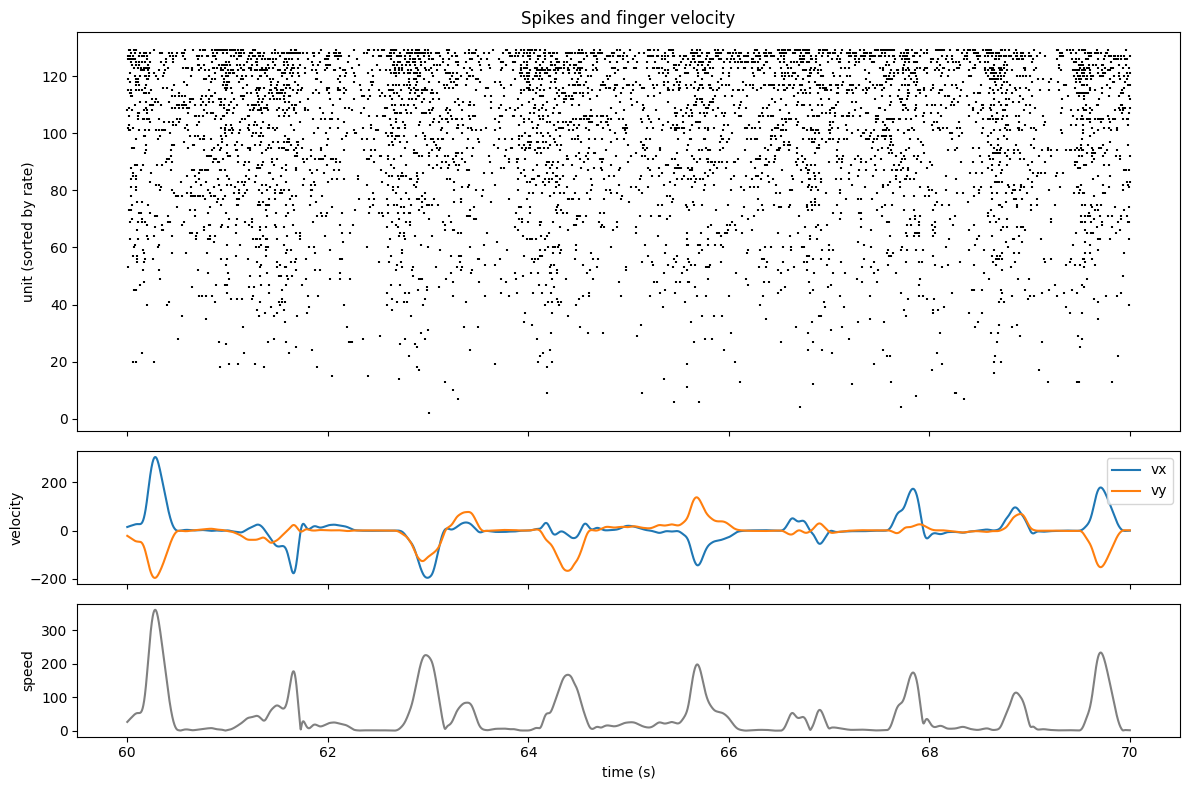

In [16]:
t_s = df.index.total_seconds().to_numpy()
valid = ~(df["spikes"].isna().any(axis=1) | vel.isna().any(axis=1)).to_numpy()

T0 = t_s[valid][0] + 60.0  # skip the first minute; change to explore
WIN = 10.0
win = (t_s >= T0) & (t_s < T0 + WIN)

spk = df["spikes"].to_numpy()
order = np.argsort(np.nanmean(spk, axis=0))  # low to high rate
rows, cols = np.nonzero(np.nan_to_num(spk[win][:, order]) > 0)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1, 1]})
axes[0].scatter(t_s[win][rows], cols, s=1, marker="|", color="k")
axes[0].set_ylabel("unit (sorted by rate)")
axes[0].set_title("Spikes and finger velocity")

v = vel.to_numpy()[win]
axes[1].plot(t_s[win], v[:, 0], label="vx")
axes[1].plot(t_s[win], v[:, 1], label="vy")
axes[1].legend(loc="upper right")
axes[1].set_ylabel("velocity")

axes[2].plot(t_s[win], np.linalg.norm(v, axis=1), color="gray")
axes[2].set_ylabel("speed")
axes[2].set_xlabel("time (s)")
plt.tight_layout()

Text(0.5, 1.0, 'Finger position, 10 s')

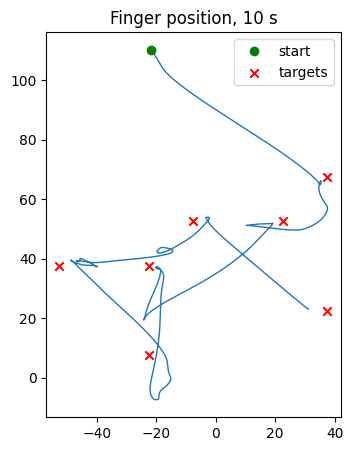

In [17]:
# The finger trajectory over the same window, with targets.
pos = df["finger_pos"].to_numpy()[win]
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(pos[:, 0], pos[:, 1], lw=1)
ax.plot(pos[0, 0], pos[0, 1], "go", label="start")
if "target_pos" in df:
    tgt = df["target_pos"].to_numpy()[win]
    tgt = np.unique(tgt[~np.isnan(tgt).any(axis=1)], axis=0)
    ax.scatter(tgt[:, 0], tgt[:, 1], marker="x", color="r", label="targets")
ax.set_aspect("equal")
ax.legend()
ax.set_title(f"Finger position, {WIN:.0f} s")

## 3. Firing rates

Typical cortical neurons fire from ~1 to ~50 spikes per second. Very silent units carry little information; note how many there are.

count    130.00
mean       4.03
std        3.99
min        0.08
25%        0.92
50%        2.96
75%        5.86
max       19.52
dtype: float64
units below 0.5 Hz: 19


Text(0, 0.5, 'n units')

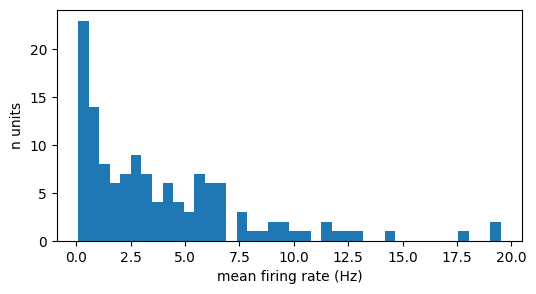

In [18]:
rates_hz = df["spikes"].mean() / (dataset.bin_width / 1000)
print(rates_hz.describe().round(2))
print("units below 0.5 Hz:", int((rates_hz < 0.5).sum()))

plt.figure(figsize=(6, 3))
plt.hist(rates_hz, bins=40)
plt.xlabel("mean firing rate (Hz)")
plt.ylabel("n units")

## 4. Bin to 20 ms

`resample` sums spikes into 20 ms bins and downsamples the behaviour. It modifies `dataset` in place, so `df` above (1 ms) is no longer what `dataset.data` holds.

Check two facts that matter for week 2: counts are still integers, and the largest count fits in a `uint8` (the C++ `step` takes `const uint8_t*`).

In [22]:
BIN_MS = 20
dataset.resample(BIN_MS)
df20 = dataset.data

counts = df20["spikes"].to_numpy()
V = df20["finger_vel"].to_numpy()
c = counts[~np.isnan(counts).any(axis=1)]

print("binned shape (bins, units):", counts.shape)
print("all integers:", bool(np.all(c == np.round(c))))
print("max count in one bin:", int(c.max()), "(uint8 max is 255)")
print("count histogram 0..5:", np.bincount(c.astype(int).ravel(), minlength=6)[:6])

Dataset already at 20 ms resolution, skipping resampling...


binned shape (bins, units): (32455, 130)
all integers: True
max count in one bin: 3 (uint8 max is 255)
count histogram 0..5: [3893251  308138   15697     114       0       0]


## 5. See the tuning

For each unit, average its spike count according to the direction the finger is moving ~100 ms later (5 bins). Only moving periods count (speed above the median). A tuned unit draws a lopsided blob pointing at its preferred direction. This is the signal every decoder in the project exploits.

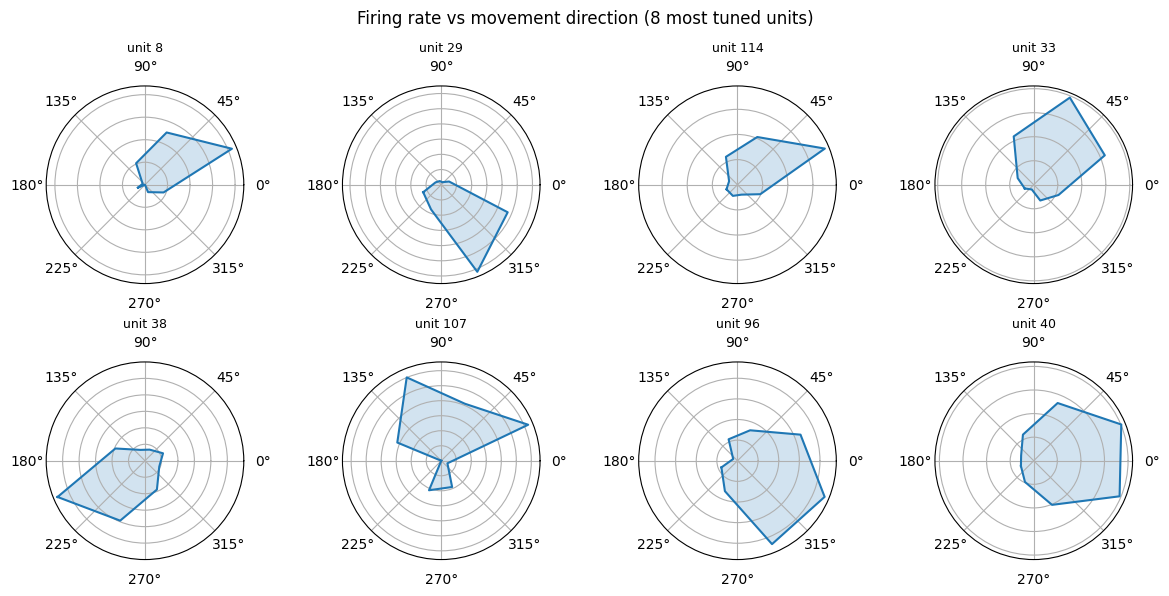

In [23]:
LAG = 5  # bins (100 ms): spikes at t vs velocity at t + LAG

Xc, Vf = counts[:-LAG], V[LAG:]
ok = ~(np.isnan(Xc).any(axis=1) | np.isnan(Vf).any(axis=1))
Xc, Vf = Xc[ok], Vf[ok]

speed = np.linalg.norm(Vf, axis=1)
moving = speed > np.median(speed)
theta = np.arctan2(Vf[moving, 1], Vf[moving, 0])
N_DIR = 8
sector = np.clip(((theta + np.pi) / (2 * np.pi) * N_DIR).astype(int), 0, N_DIR - 1)
centers = -np.pi + (np.arange(N_DIR) + 0.5) * 2 * np.pi / N_DIR

Xm = Xc[moving]
tuning_hz = np.stack([Xm[sector == k].mean(axis=0) for k in range(N_DIR)]) / (BIN_MS / 1000)
depth = (tuning_hz.max(0) - tuning_hz.min(0)) / (tuning_hz.mean(0) + 1e-9)
top = np.argsort(depth)[::-1][:8]

fig, axes = plt.subplots(2, 4, figsize=(12, 6), subplot_kw={"projection": "polar"})
for ax, u in zip(axes.ravel(), top):
    ang = np.r_[centers, centers[0]]
    r = np.r_[tuning_hz[:, u], tuning_hz[0, u]]
    ax.plot(ang, r)
    ax.fill(ang, r, alpha=0.2)
    ax.set_title(f"unit {u}", fontsize=9)
    ax.set_yticklabels([])
fig.suptitle("Firing rate vs movement direction (8 most tuned units)")
plt.tight_layout()

## 6. A first decoder, and a first look at the lag

The simplest possible decoder: velocity(t + lag) = W · counts(t) + b, fitted by least squares on the first 70% of the session and scored by R² on the rest. Sweep the lag from 0 to 200 ms. If neurons really lead movement, R² should peak somewhere around 100 ms, not at 0.

This is only a preview: on Day 2 you will redo it properly (train/val/test split, several bins of history, ridge penalty).

best lag: 140 ms, mean R² = 0.180


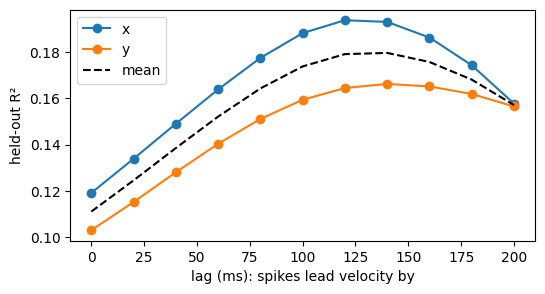

In [24]:
def r2(y, yhat):
    return 1 - ((y - yhat) ** 2).sum(0) / ((y - y.mean(0)) ** 2).sum(0)


def lag_r2(X, V, lag, train_frac=0.7):
    Xl, Vl = X[: len(X) - lag], V[lag:]
    ok = ~(np.isnan(Xl).any(axis=1) | np.isnan(Vl).any(axis=1))
    Xl, Vl = Xl[ok], Vl[ok]
    A = np.c_[Xl, np.ones(len(Xl))]  # constant column = bias b
    split = int(train_frac * len(A))  # time-ordered, no shuffling
    W, *_ = np.linalg.lstsq(A[:split], Vl[:split], rcond=None)
    return r2(Vl[split:], A[split:] @ W)


lags = np.arange(0, 11)  # 0..200 ms in 20 ms bins
scores = np.array([lag_r2(counts, V, L) for L in lags])

plt.figure(figsize=(6, 3))
plt.plot(lags * BIN_MS, scores[:, 0], "o-", label="x")
plt.plot(lags * BIN_MS, scores[:, 1], "o-", label="y")
plt.plot(lags * BIN_MS, scores.mean(1), "k--", label="mean")
plt.xlabel("lag (ms): spikes lead velocity by")
plt.ylabel("held-out R²")
plt.legend()
best = lags[scores.mean(1).argmax()]
print(f"best lag: {best * BIN_MS} ms, mean R² = {scores.mean(1).max():.3f}")

## Notes for Day 1 (fill in)

- Number of units:  130
- Velocity field name and units: finger_vel, m/s
- Session length, fraction of NaN rows: 10.8min, 0.0005 of NANs
- Max spike count per 20 ms bin: 3
- Best lag in the preview, and its R²: 140ms, R² = 0.180
- Anything surprising:

## Next (Day 2)

Move loading, binning and the 70/10/20 causal split into `python/data.py`, pick the lag on the validation split, and build the Wiener filter (ridge regression on the last 5–10 bins).